# PGA Tour Player Comparison

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sjsardar/S2PGAGOLF/blob/main/PGA_Player_Comparison.ipynb)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

url = "https://raw.githubusercontent.com/jordanr-johnson/PGA-Tournament-Python-Project/main/ASA%20All%20PGA%20Raw%20Data%20-%20Tourn%20Level.csv"
df = pd.read_csv(url)
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df.shape

(36864, 34)

## Similar players

In [2]:
sg_cols = ["sg_ott", "sg_app", "sg_arg", "sg_putt"]
d = df.dropna(subset=sg_cols).copy()
d["to_par"] = d["strokes"] - d["hole_par"]
d["top10"] = d["pos"] <= 10

g = d.groupby("player")
rounds = g["n_rounds"].sum()
players = pd.DataFrame({c: (d[c] * d["n_rounds"]).groupby(d["player"]).sum() / rounds for c in sg_cols})
players["score_per_round"] = g["to_par"].sum() / rounds
players["cut_pct"] = g["made_cut"].mean() * 100
players["top10_pct"] = g["top10"].mean() * 100
players["events"] = g.size()
players = players[players["events"] >= 20]

features = sg_cols + ["score_per_round", "cut_pct", "top10_pct"]
z = (players[features] - players[features].mean()) / players[features].std()
player_list = sorted(players.index)

def show_similar(player, n_similar=10):
    dist = np.sqrt(((z - z.loc[player]) ** 2).sum(axis=1))
    result = players.assign(similarity=100 * (1 - dist / dist.max()))
    result = result.sort_values("similarity", ascending=False).head(n_similar + 1)
    names = result.index.tolist()
    n = len(names)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 0.5 * n + 1.8), sharey=True,
                                        gridspec_kw={"width_ratios": [2, 3, 2.4]})

    sim = result["similarity"].values
    ax1.barh(range(n), sim, color=["gray"] + ["tab:blue"] * (n - 1))
    for i, s in enumerate(sim):
        ax1.text(s - 1, i, "selected" if i == 0 else f"{s:.0f}%", va="center", ha="right", color="white", fontsize=9)
    ax1.set_yticks(range(n))
    ax1.set_yticklabels(names)
    ax1.invert_yaxis()
    ax1.set_xlim(0, 100)
    ax1.set_title("Similarity")
    ax1.spines[["top", "right"]].set_visible(False)

    sg_vals = result[sg_cols].values
    lim = np.abs(sg_vals).max()
    ax2.imshow(sg_vals, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    for i in range(n):
        for j in range(4):
            v = sg_vals[i, j]
            ax2.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9,
                     color="white" if abs(v) > 0.6 * lim else "black")
    ax2.set_xticks(range(4))
    ax2.set_xticklabels(["Off Tee", "Approach", "Around Green", "Putting"])
    ax2.xaxis.tick_top()
    ax2.set_title("Strokes gained per round (blue = above tour avg, red = below)", pad=28)

    cols = [("score_per_round", "Score/Rd", "{:+.2f}"), ("cut_pct", "Cut %", "{:.0f}%"),
            ("top10_pct", "Top 10 %", "{:.0f}%"), ("events", "Events", "{:.0f}")]
    for j, (c, lab, fmt) in enumerate(cols):
        for i in range(n):
            ax3.text(j, i, fmt.format(result[c].iloc[i]), ha="center", va="center", fontsize=10)
        ax3.text(j, -0.9, lab, ha="center", va="bottom", fontsize=10)
    ax3.set_xlim(-0.5, len(cols) - 0.5)
    ax3.set_title("Scoring & results", pad=28)
    ax3.axis("off")

    fig.suptitle(f"Players most similar to {player}", fontsize=13)
    plt.tight_layout()
    plt.show()

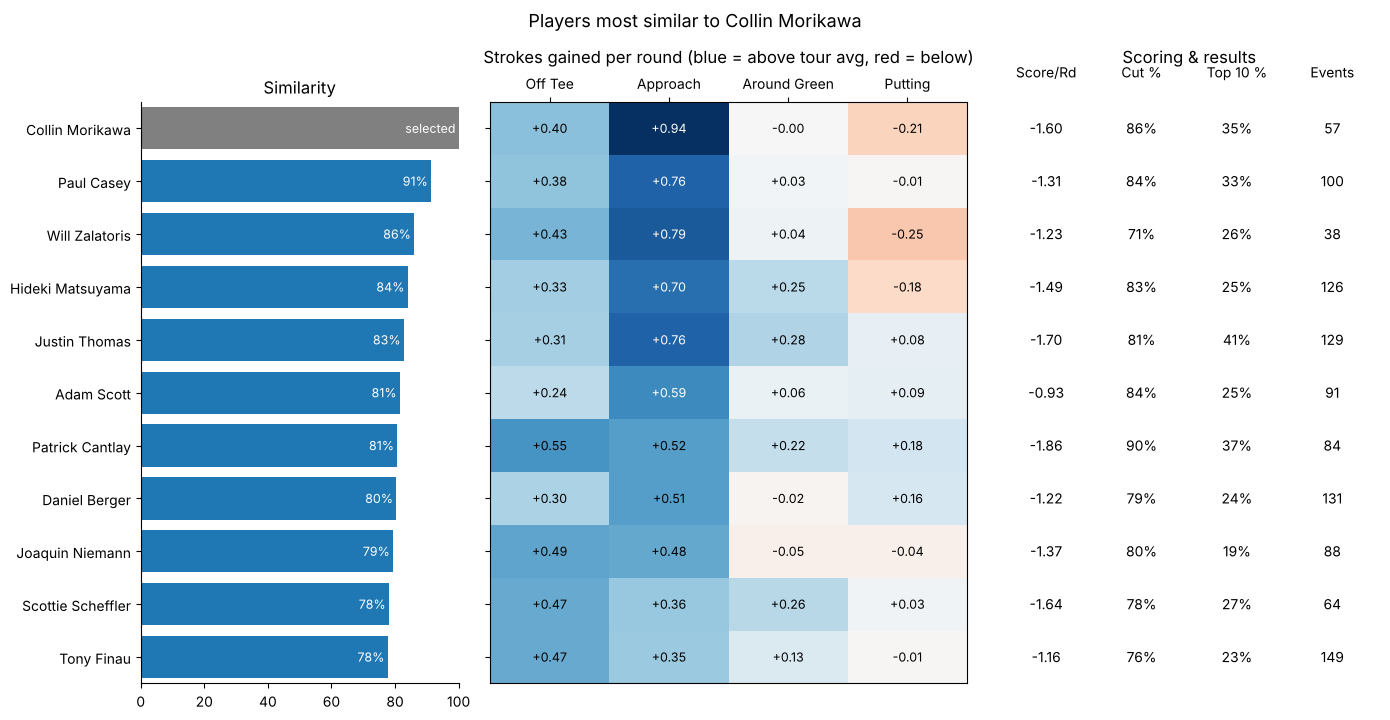

In [3]:
show_similar("Collin Morikawa")

In [4]:
interact(show_similar,
         player=widgets.Dropdown(options=player_list, value="Collin Morikawa", description="Player"),
         n_similar=widgets.IntSlider(value=10, min=5, max=20, description="Players"));

## Strokes gained vs. tour average

In [5]:
sg_all = sg_cols + ["sg_total"]
sg_data = df.dropna(subset=sg_all)

def show_sg(player):
    p = sg_data[sg_data["player"] == player]
    values = [(p[c] * p["n_rounds"]).sum() / p["n_rounds"].sum() for c in sg_all]
    labels = ["Off the Tee", "Approach", "Around the Green", "Putting", "Total"]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(labels, values, color=["tab:blue" if v >= 0 else "tab:red" for v in values])
    ax.axvline(0, color="black", linewidth=1)
    ax.invert_yaxis()
    for i, v in enumerate(values):
        ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right")
    ax.set_xlim(min(values + [0]) - 0.3, max(values) + 0.3)
    ax.set_xlabel("Strokes gained per round (0 = tour average)")
    ax.set_title(f"{player}: Strokes Gained vs. Tour Average ({len(p)} events)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

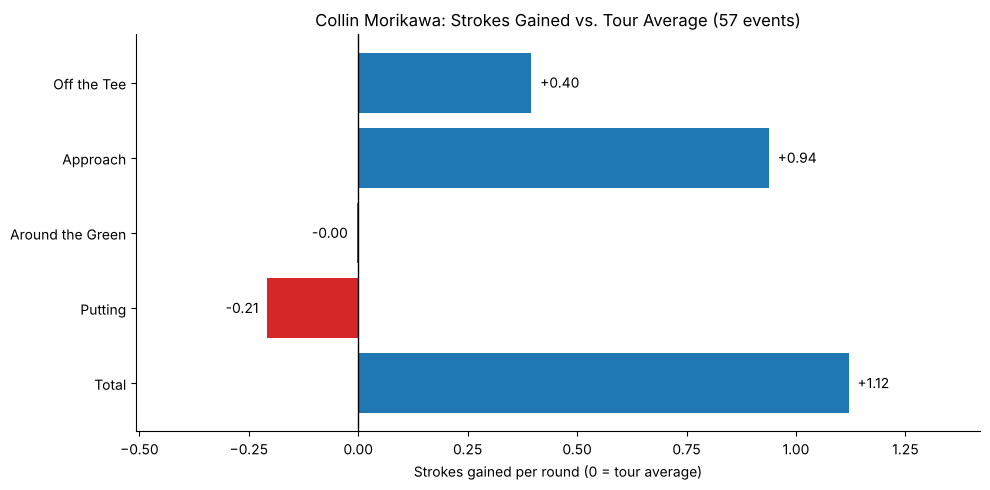

In [6]:
show_sg("Collin Morikawa")

In [7]:
interact(show_sg, player=widgets.Dropdown(options=player_list, value="Collin Morikawa", description="Player"));